In [2]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from lab8.model import WeatherLSTM
from torch import nn

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 16,
    "font.family": "Times New Roman",
})

# 1. Загрузка данных и модели

In [3]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Запустите ноутбук из папки lab8 или lab8/notebooks.")

In [4]:
torch.set_num_threads(1)
required_files = [
    "prepared.npz", "preprocessing.json", "observations.csv",
    "lstm.pt", "selection.json", "seasonal_coef.npy",
]
for name in required_files:
    if not (ARTIFACTS_DIR / name).is_file():
        raise FileNotFoundError(f"Нет {name}. Выполните ноутбуки 1 и 2.")
    
meta = json.loads((ARTIFACTS_DIR / 'preprocessing.json').read_text(encoding='utf-8'))
selection = json.loads((ARTIFACTS_DIR / 'selection.json').read_text(encoding='utf-8'))

assert hashlib.sha256((PROJECT_ROOT / 'data/raw/seattle-weather.csv').read_bytes()).hexdigest() == meta['raw_sha256']

with np.load(ARTIFACTS_DIR / 'prepared.npz', allow_pickle=False) as data:
    X_test, y_test = data['X_test'].copy(), data['y_test'].copy()
    dates = pd.to_datetime(data['dates_test'])


data_hashes = {
    name: hashlib.sha256((ARTIFACTS_DIR / name).read_bytes()).hexdigest()
    for name in ["prepared.npz", "preprocessing.json", "observations.csv"]
}

In [8]:
checkpoint = torch.load(
    ARTIFACTS_DIR / "lstm.pt",
    map_location="cpu",
    weights_only=True,
)

model = WeatherLSTM(**checkpoint["config"])
model.load_state_dict(checkpoint["state_dict"])
model.eval()

WeatherLSTM(
  (lstm): LSTM(6, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)

## 2. Прогноз на тесте

Возвращаем температуру в °C. Все модели сравниваются на одинаковых датах.


In [ ]:
with torch.no_grad():
    prediction = model(torch.from_numpy(X_test)).numpy() * meta['y_std'] + meta['y_mean']
    
actual = y_test * meta['y_std'] + meta['y_mean']
observations = pd.read_csv(ARTIFACTS_DIR / 'observations.csv', parse_dates=['date']).set_index('date')

np.testing.assert_allclose(actual, observations.loc[dates, 'temp_max'], atol=1e-5)

angle = 2 * np.pi * (dates.dayofyear - 1) / np.where(dates.is_leap_year, 366, 365)
design = np.column_stack([np.ones(len(dates)), np.sin(angle), np.cos(angle)])
results = pd.DataFrame({
    'actual': actual, 'lstm': prediction,
    'persistence': observations.temp_max.shift(1).reindex(dates).to_numpy(),
    'mean_7': observations.temp_max.shift(1).rolling(7).mean().reindex(dates).to_numpy(),
    'seasonal': design @ np.load(ARTIFACTS_DIR / 'seasonal_coef.npy', allow_pickle=False)}, index=dates)

assert np.isfinite(results.to_numpy()).all()
assert len(results) == 365

display(results.head())

,actual,lstm,persistence,mean_7,seasonal
2015-01-01,5.599999,4.472206,3.3,6.028571,7.156347
2015-01-02,5.599999,5.273743,5.6,5.714286,7.106184
2015-01-03,4.999999,6.633964,5.6,5.714286,7.058558
2015-01-04,10.600000,6.205147,5.0,5.085714,7.013483
2015-01-05,12.200000,9.994759,10.6,5.642857,6.970973


## 3. Метрики

| Метрика | Смысл |
|---|---|
| MAE | Средняя абсолютная ошибка, °C |
| RMSE | Ошибка с большим штрафом за крупные отклонения, °C |
| Bias | Среднее «прогноз − факт», °C; плюс означает завышение |
| R² | Сравнение с постоянным средним теста; может быть отрицательным |
| Skill MAE | 1 − MAE модели / MAE persistence; положительное значение означает улучшение |

MAE и RMSE: меньше — лучше. Модель уже выбрана по validation. По тесту выбор не меняем.
MAPE не используем: температура в °C бывает нулевой и отрицательной.


In [ ]:
def metrics(y, prediction):
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    assert y.shape == prediction.shape and len(y) > 0
    error = prediction - y
    denominator = np.sum((y - y.mean())**2)
    return {'MAE_C': np.mean(np.abs(error)), 'RMSE_C': np.sqrt(np.mean(error**2)),
            'Bias_C': np.mean(error),
            'R2': 1 - np.sum(error**2) / denominator if denominator > 0 else np.nan}

In [8]:
scores = pd.DataFrame({name: metrics(results.actual, results[name])
                      for name in ['lstm', 'persistence', 'mean_7', 'seasonal']}).T
baseline_mae = scores.loc['persistence', 'MAE_C']
scores['Skill_MAE_vs_persistence'] = 1 - scores.MAE_C / baseline_mae if baseline_mae > 0 else np.nan
chosen = selection['selected_by_validation_rmse']
scores['selected_on_validation'] = scores.index == chosen
display(scores.round(3))
print(f'Заранее выбранная модель: {chosen}; test MAE = {scores.loc[chosen, "MAE_C"]:.2f} °C')
skill = scores.loc['lstm', 'Skill_MAE_vs_persistence']
print(f'LSTM: изменение MAE относительно persistence = {skill:.1%} (плюс означает улучшение).')


,MAE_C,RMSE_C,Bias_C,R2,Skill_MAE_vs_persistence,selected_on_validation
lstm,2.048,2.596,-0.370,0.874,0.085,True
persistence,2.240,2.907,-0.006,0.842,0.000,False
mean_7,2.718,3.471,-0.003,0.775,-0.214,False
seasonal,3.284,4.075,-1.761,0.689,-0.466,False


Заранее выбранная модель: lstm; test MAE = 2.05 °C
LSTM: изменение MAE относительно persistence = 8.5% (плюс означает улучшение).


## 4. Анализ ошибок

Сравнение фактической температуры и прогнозов.


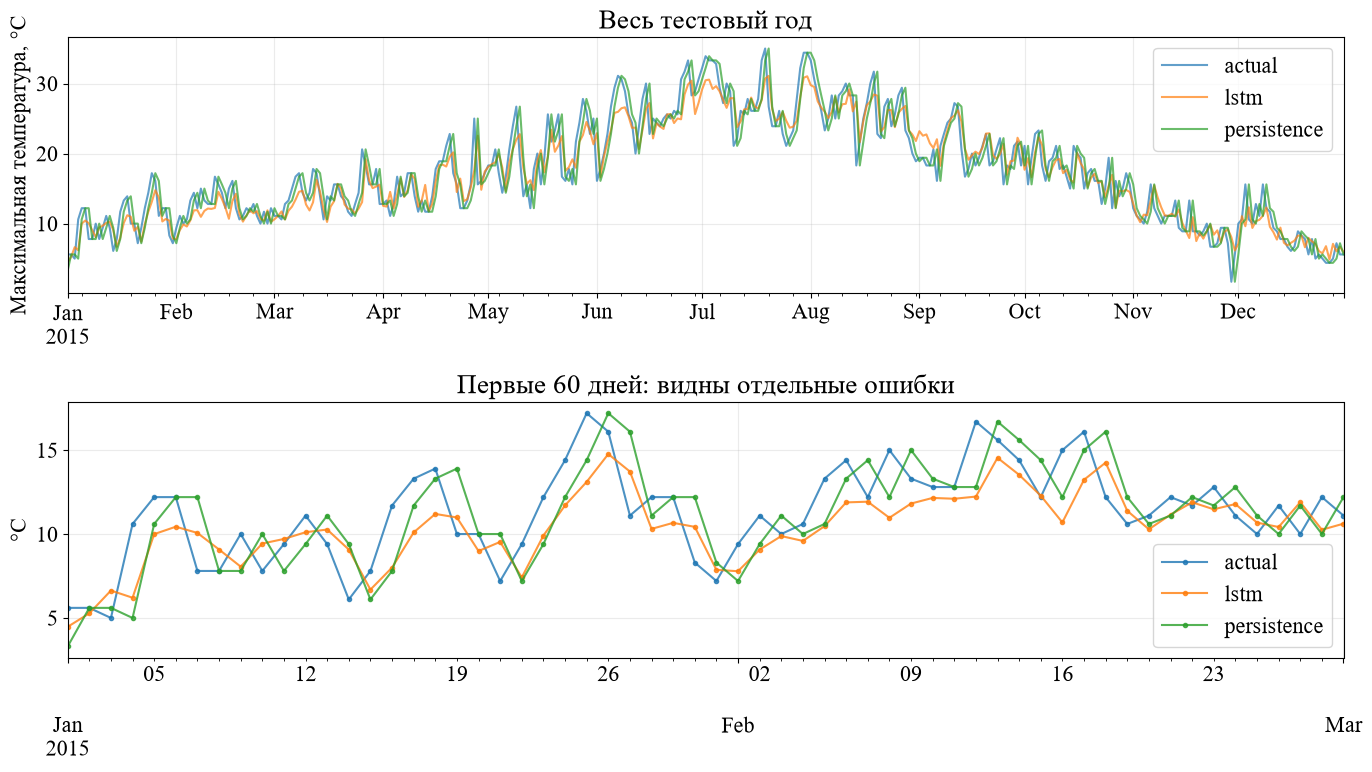

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
results[['actual', 'lstm', 'persistence']].plot(ax=axes[0], alpha=.7)
axes[0].set(title='Весь тестовый год', ylabel='Максимальная температура, °C')
results.iloc[:60][['actual', 'lstm', 'persistence']].plot(ax=axes[1], marker='.', alpha=.8)
axes[1].set(title='Первые 60 дней: видны отдельные ошибки', ylabel='°C')
plt.tight_layout()
plt.show()


Распределение ошибок LSTM. Положительная ошибка означает завышение температуры.


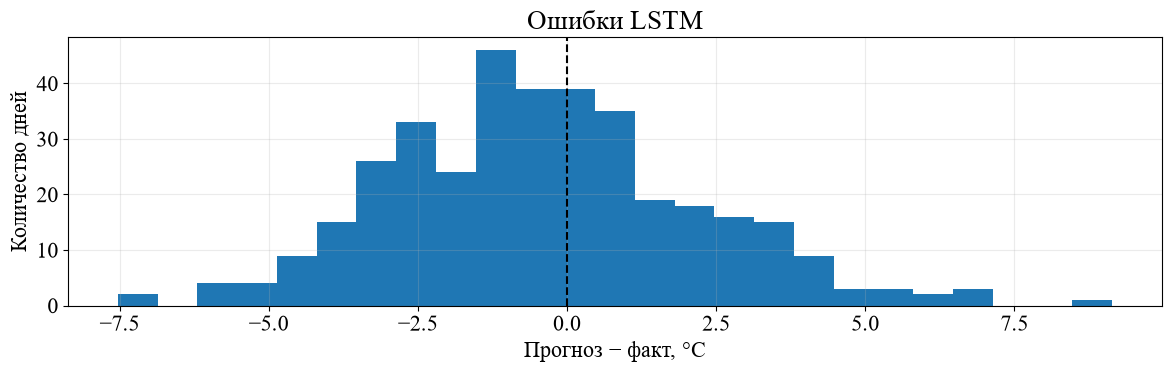

In [ ]:
error = results["lstm"] - results["actual"]
error.plot.hist(bins=25)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Прогноз − факт, °C")
plt.ylabel("Количество дней")
plt.title("Ошибки LSTM")
plt.tight_layout()
plt.show()

Факт и прогноз. На диагонали ошибка равна нулю.


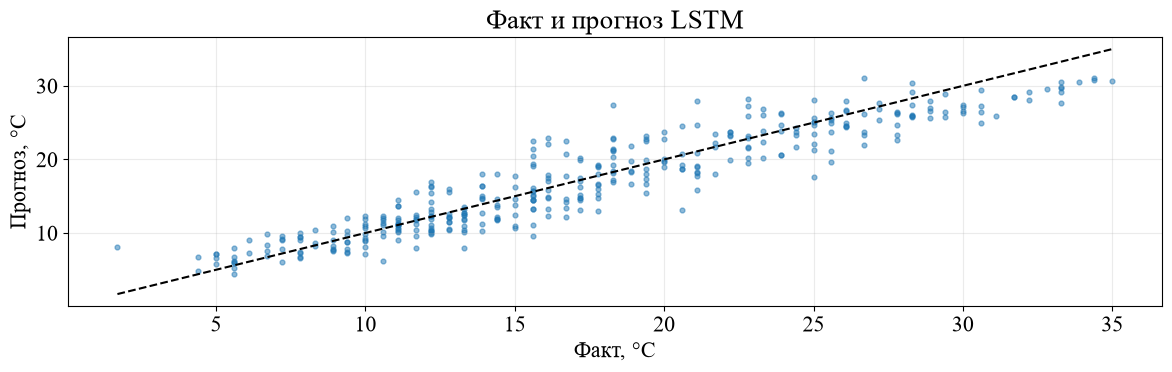

In [11]:
plt.figure()
plt.scatter(results["actual"], results["lstm"], s=12, alpha=0.5)
lower = results[["actual", "lstm"]].min().min()
upper = results[["actual", "lstm"]].max().max()
plt.plot([lower, upper], [lower, upper], color="black", linestyle="--")
plt.xlabel("Факт, °C")
plt.ylabel("Прогноз, °C")
plt.title("Факт и прогноз LSTM")
plt.tight_layout()
plt.show()

Связь ошибок с предыдущими днями. Лаг — сдвиг в днях.


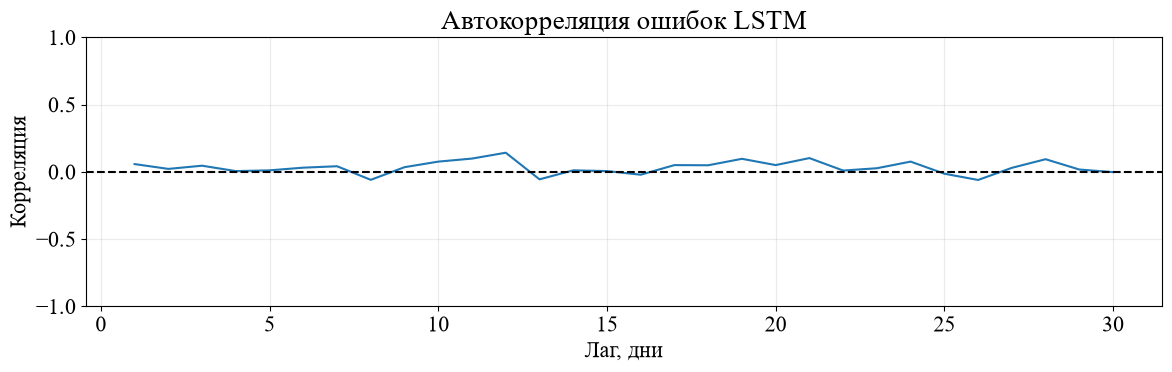

In [12]:
lags = range(1, 31)
correlations = []
for lag in lags:
    correlations.append(error.corr(error.shift(lag)))

plt.figure()
plt.plot(lags, correlations)
plt.axhline(0, color="black", linestyle="--")
plt.ylim(-1, 1)
plt.xlabel("Лаг, дни")
plt.ylabel("Корреляция")
plt.title("Автокорреляция ошибок LSTM")
plt.tight_layout()
plt.show()

MAE по месяцам и десять наибольших ошибок LSTM.


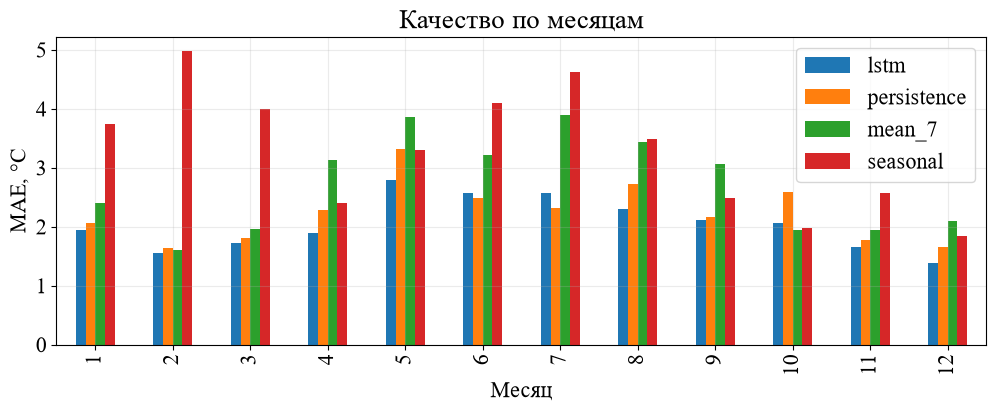

,actual,lstm,persistence,mean_7,seasonal,abs_error
2015-08-14,18.299999,27.439796,28.3,28.157143,23.996139,9.139797
2015-03-26,20.600000,13.070477,14.4,13.257143,11.643669,7.529524
2015-04-27,25.000000,17.637634,15.6,15.557143,16.464330,7.362366
2015-04-28,15.600000,22.544920,25.0,15.871429,16.618870,6.944920
2015-06-01,16.100000,22.912865,25.0,23.342857,21.415672,6.812864
2015-07-10,21.100000,27.909840,28.9,30.700000,24.492056,6.809839
2015-11-29,1.700000,8.075392,7.2,8.085714,10.100320,6.375392
2015-05-18,25.600000,19.597885,19.4,16.357143,19.590512,6.002115
2015-12-03,15.600000,9.627485,10.6,7.700000,9.625210,5.972515
2015-09-06,16.100000,22.044872,20.6,19.271429,22.016302,5.944872


In [13]:
monthly = pd.DataFrame({name: (results[name] - results.actual).abs().groupby(results.index.month).mean()
                        for name in ['lstm', 'persistence', 'mean_7', 'seasonal']})
monthly.plot.bar()
plt.ylabel('MAE, °C')
plt.xlabel('Месяц')
plt.title('Качество по месяцам')
plt.show()
display(results.assign(abs_error=error.abs()).nlargest(10, 'abs_error'))

## 5. Сохранение результатов

Прогнозы, общие метрики и MAE по месяцам сохраняются отдельно.


In [14]:
results.to_csv(ARTIFACTS_DIR / "test_predictions.csv", index_label="date")
scores.to_csv(ARTIFACTS_DIR / "test_metrics.csv", index_label="model")
monthly.to_csv(ARTIFACTS_DIR / "monthly_mae.csv", index_label="month")
print(f"Результаты сохранены в {ARTIFACTS_DIR}")

Результаты сохранены в C:\Users\sadovets\Dev\BMSTU\IU1_ML\sem2\lab8\artifacts


Оценка относится к одному тестовому году и одному запуску.
После просмотра теста он не является независимым для дальнейшего подбора параметров.
